<a href="https://colab.research.google.com/github/giovanardo/DATA201-labs/blob/main/new_copy_of_Week8_Regularization_Hitters_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Regularization and Model Complexity: Ridge vs. Lasso


### Learning goals
By the end of this lab, you will be able to:
1. Fit a linear regression baseline and identify overfitting using training and test error.
2. Explain how ridge (L2) and lasso (L1) change the fitted coefficients.
3. Select regularization strength (`alpha`) using **5-fold cross-validation on the training set**.
4. Compare model performance fairly on an untouched test set.
5. Explain the tradeoff among bias, variance, prediction accuracy, and interpretability.

**Important connection:** We used regularization with logistic regression in Week 7. Today, we use **linear regression** because salary is a continuous outcome, not a class. Classification metrics such as accuracy and ROC-AUC are **not** appropriate here; we use MSE, RMSE, and R².

### Part 1 — Load the ISLP Hitters dataset

**Dataset background:** The data contain professional baseball players' 1986 statistics and their 1987 salaries. `Salary` is reported in **thousands of dollars**. The original dataset has 322 rows; some salary values are missing. This is the dataset used in ISLP's Chapter 6 regularization lab.

**Colab:** Run the next cell to install ISLP. You need to run it each time in Colab.

In [ ]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [ ]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [ ]:
hitters['Salary'].max()*1000
hitters['Salary'].min()*1000

67500.0

**Discuss:** Which variable is the outcome? Which columns are categorical? Why must we exclude players with missing Salary values when training and evaluating our model?

We remove rows with missing salary. For other predictors, this dataset does not require additional missing-value handling after this step. We will encode categorical variables using a pipeline so their transformations are learned correctly in cross-validation.

Since the (NA) are in Salary column only, dropna(subset=['Salary']) removes rows where Salary is missing. Then .copy() creates a separate DataFrame containing the remaining rows. and [hitters = ] assigns that new DataFrame to the variable hitters.

In [ ]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


### Part 2 - Prepare the data and build a baseline

Why scale? Regularization penalizes **coefficients**. Salary predictors such as career at-bats and years played have different units, so comparing coefficient magnitudes is unfair unless numerical inputs are standardized.

We use the **same preprocessing** for all three models. The pipeline protects the training folds during cross-validation: the scaler fits only on each fold's training portion.

In [ ]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ]) #scaling z-scores and changing categorical into numbers (0 and 1)

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
]) #model linear regression and learn

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    } #predicting a quantitive variable

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


Training R²: Measures how much variation in Y is explained by the model on the data used to fit it.

Here we are find the Test R² which measures how well the model predicts variation in Y for new observations that were not used during training.

RMSE is measured in **thousands of dollars**, like `Salary`. Lower RMSE is better; higher R² is better.

A large gap between training RMSE and test RMSE can indicate overfitting, but a small gap alone does not prove generalization.

**Question 1:** What is the baseline test RMSE? Explain why the pattern (the training RMSE smaller than the test RMSE) is common.

### Part 3 - The regularization dial: ridge vs. lasso

Ordinary linear regression finds the coefficients that minimize Residual Sum of Squares(RSS) on the training data.

Ridge and lasso also try to minimize RSS, but they add a penalty for large coefficients.

- **Ridge (L2):** training RSS + α × sum of squared coefficients. It generally keeps all predictors but shrinks their weights.
- **Lasso (L1):** training RSS + α × sum of absolute coefficients. It can shrink some weights exactly to zero.

**In ISLP, the penalty strength is called λ (lambda); scikit-learn uses `alpha` for `Ridge` and `Lasso`.** A larger α means stronger regularization. The intercept is not penalized.

**Important:** The exact numerical relationship depends on how the software defines and scales the loss function. Also, an alpha of 1 in ridge is not directly equivalent in effect to an alpha of 1 in lasso.

In Part 3, we will the same training set and change α and observe what happens to the coefficients. The goal is to understand regularization. In Part 4, we will use cross-validation to find the best α.

Note: We calculated the sum of the absolute coefficients for both Ridge and Lasso to measure how much the coefficients shrink as alpha increases. This is only a summary measure. Ridge still uses an L2 penalty, while Lasso uses an L1 penalty during training.

In [ ]:
alpha_examples = [0.01, 0.1, 1, 10, 100, 1000] #thats the penalty; choosing hyper parameter, dont use it in real life.
rows = []
for kind, estimator in [('Ridge', Ridge()), ('Lasso', Lasso(max_iter=30000))]: #"Ridge can often calculate its coefficients directly,
                                                                                #while Lasso generally needs an iterative process to find its coefficients
    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Coefficient L1 size': float(np.sum(np.abs(coefs))), #sum of the absolute values of all coefficients
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Coefficient L1 size,Training RMSE
0,Ridge,0.01,19,2855.93,289.33
1,Ridge,0.10,19,2608.64,289.38
2,Ridge,1.00,19,1893.70,290.72
3,Ridge,10.00,19,854.92,298.20
4,Ridge,100.00,19,500.83,309.50
5,Ridge,1000.00,19,265.70,344.14
6,Lasso,0.01,19,2861.11,289.33
7,Lasso,0.10,19,2589.13,289.38
8,Lasso,1.00,18,1731.28,290.91
9,Lasso,10.00,9,524.31,303.10


**RIDGE**: COEFICCIENTS STAIS THE SAME, THE TRAINING ERROR INCREASES AS THE ALPHA INCREASES; THE MODEL IS BECOMING MORE BIAS. DOESNT LEARN

**LASSO**: INCREASING ALPHA, COEFICIENTS DESAPEAR; THE TRAINING ERROR INCREASES AS THE COEFFICIENT INCREASES

- Ridge: The coefficients generally shrink as alpha increases, but predictors remain in the model.
- Lasso: Some coefficients become zero as alpha increases, effectively removing predictors.
- Training RMSE: Stronger regularization generally increases training error because the model has less freedom to fit the data.

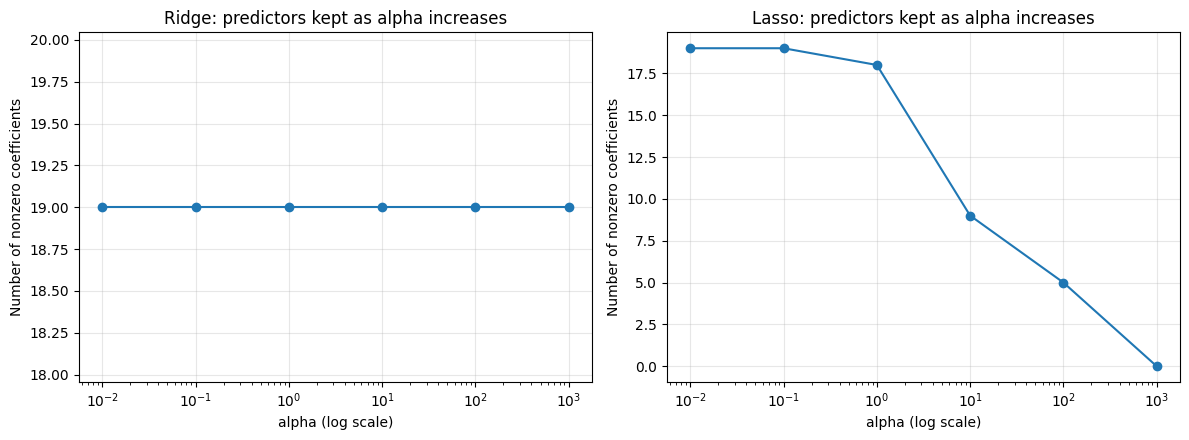

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, kind in zip(axes, ['Ridge', 'Lasso']):
    subset = alpha_table[alpha_table['Model'] == kind]
    ax.semilogx(subset['alpha'], subset['Nonzero coefficients'], marker='o')
    ax.set_title(f'{kind}: predictors kept as alpha increases')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('Number of nonzero coefficients')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Question 2:** How does the number of nonzero coefficients change for ridge and lasso? What happens to training RMSE as α increases? Why does a higher training error **not necessarily** mean a worse model?


### Part 4 - Choose α using cross-validation
We must not choose α because it gives the best **test** result. The test set is being saved for the final evaluation.

We'll use the Week 6–7 workflow:

**Pipeline → GridSearchCV → 5-fold CV on training data → choose α → refit on all training data → test once**.

For ridge, try more α values spanning weak to strong penalties. Lasso also uses a logarithmic grid. Both models are assessed with the **same folds and metric**. The scoring is negative MSE because scikit-learn selects the highest score.

Why negative mean squared error?
Ordinarily, lower MSE is better. However, scikit-learn's GridSearchCV is designed to select the model with the highest score. Therefore, it uses negative MSE.

In [ ]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42) #spliting in 5, shuffle=True: random as possible.

ridge_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()), ('model', Ridge())]),
    {'model__alpha': np.logspace(-2, 5, 40)}, #power of 10 cutted in 40 parts
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1 #Uses all available CPU cores to speed up the computations
)
lasso_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()),
              ('model', Lasso(max_iter=30000))]),
    {'model__alpha': np.logspace(-2, 4, 40)}, #stop at 4, because the coef will desapear
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
) #neg_mean_squared: find the error, the high error is classified as good, but we know the higer the error is, the worst

ridge_grid.fit(X_train, y_train)
lasso_grid.fit(X_train, y_train)

print('Best ridge alpha:', ridge_grid.best_params_['model__alpha'])
print('Best ridge CV RMSE:', np.sqrt(-ridge_grid.best_score_)) #negative values
print('Best lasso alpha:', lasso_grid.best_params_['model__alpha'])
print('Best lasso CV RMSE:', np.sqrt(-lasso_grid.best_score_))

Best ridge alpha: 203.09176209047348
Best ridge CV RMSE: 340.7959841903925
Best lasso alpha: 24.244620170823307
Best lasso CV RMSE: 349.49427101392234


40 alpha x 5 folds = 200 across Ridge and Lasso, that is 400 cross-validation fits, plus one final refit for each model using all of X_train and y_train.

n_jobs=-1 tells GridSearchCV to use all available CPU cores to run multiple model fits at the same time, potentially speeding up cross-validation.

In Google Colab, these computations run on Colab's remote CPU, not your personal computer. When GridSearchCV finishes running, it stops using the CPU cores for that task, making them available for other computations.

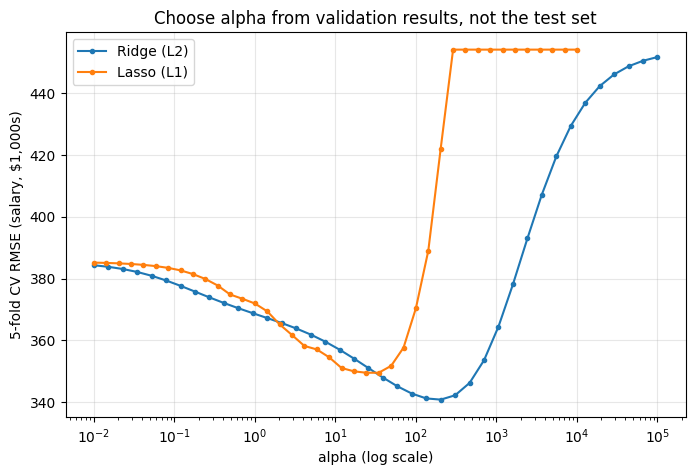

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, grid in [('Ridge (L2)', ridge_grid), ('Lasso (L1)', lasso_grid)]:
    a = grid.cv_results_['param_model__alpha'].astype(float)
    rmse = np.sqrt(-grid.cv_results_['mean_test_score'])
    ax.semilogx(a, rmse, marker='.', label=label)
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('5-fold CV RMSE (salary, $1,000s)')
ax.set_title('Choose alpha from validation results, not the test set')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Question 3:** For each model, identify the best α and CV RMSE. What happens when α becomes **too large**? Explain using the word **bias**.


As α increases, regularization becomes stronger, pushing the coefficients toward zero. When α becomes too large, the model becomes overly restricted and cannot capture important relationships between the predictors and salary.

This leads to:
- Higher bias: The model is too simple to capture the underlying relationships.
- Lower variance: Predictions become less sensitive to changes in the training data.
- Underfitting: Both training and validation errors tend to increase.

The main takeaway: Regularization introduces some bias to reduce variance and potentially improve prediction accuracy. However, too much regularization creates excessive bias and increases prediction error.

In this dataset, Ridge achieves a lower CV RMSE than Lasso. This suggests that shrinking coefficients while retaining predictors works better than the sparsity encouraged by Lasso, at least for the α values tested.

### Part 5 - Final comparison on the untouched test set
`GridSearchCV` automatically refits its best pipeline on **all training rows** (`refit=True`, the default). Now we are ready to compare all three models on the same test set.

In [ ]:
#adding to "results" from previous cell
results += [
    measure('Ridge (L2, tuned)', ridge_grid.best_estimator_),
    measure('Lasso (L1, tuned)', lasso_grid.best_estimator_)
]

#Create a comparison table
comparison = pd.DataFrame(results).sort_values('Test RMSE')
display(comparison.round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41
2,"Lasso (L1, tuned)",308.33,385.62,0.31
6,"Lasso (L1, tuned)",308.33,385.62,0.31
4,"Lasso (L1, tuned)",308.33,385.62,0.31
10,"Lasso (L1, tuned)",308.33,385.62,0.31
8,"Lasso (L1, tuned)",308.33,385.62,0.31
3,"Ridge (L2, tuned)",314.93,390.26,0.30
1,"Ridge (L2, tuned)",314.93,390.26,0.30
7,"Ridge (L2, tuned)",314.93,390.26,0.30
5,"Ridge (L2, tuned)",314.93,390.26,0.30


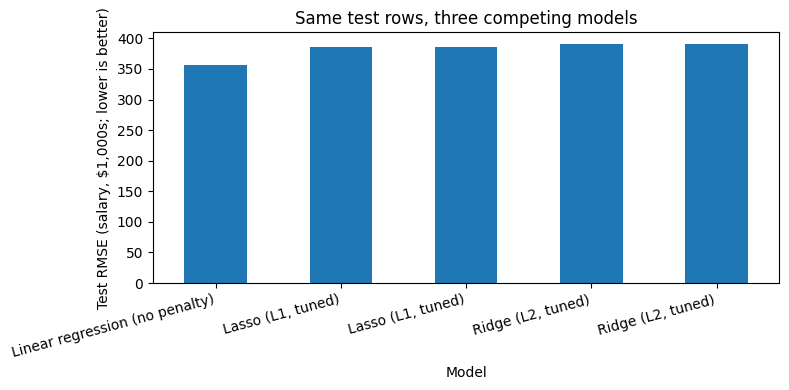

In [ ]:
ax = comparison.plot(kind='bar', x='Model', y='Test RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE (salary, $1,000s; lower is better)')
ax.set_title('Same test rows, three competing models')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

**Question 4:** Which model has the lowest test RMSE? Are the differences large enough that you would confidently call one model superior? A single test split is useful, but it is not proof that a small performance gap will persist.

**Important:** Regularization is an attempt to reduce variance by allowing some bias. Whether this improves test RMSE depends on the dataset.

### Part 6 - Interpretability: what did the model retain? Which predictors did each model keep, shrink, or eliminate?

The coefficient table below shows how the same predictors behave under ordinary least squares, tuned ridge, and tuned lasso. The numeric predictors have been standardized; categorical predictors have been encoded. This makes the three models comparable **for the same transformed feature**, though comparisons of coefficient importance across all features still require caution.

In [ ]:
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Ridge': ridge_grid.best_estimator_.named_steps['model'].coef_,
    'Lasso': lasso_grid.best_estimator_.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,OLS,Ridge,Lasso
0,num__AtBat,-252.65,21.73,0.00
1,num__Hits,379.23,40.52,104.58
2,num__HmRun,64.67,12.01,0.00
3,num__Runs,-82.33,28.62,0.00
4,num__RBI,-52.67,20.89,0.00
5,num__Walks,113.43,31.26,41.63
6,num__Years,35.91,18.01,0.00
7,num__CAtBat,-318.63,27.32,0.00
8,num__CHits,-136.22,32.96,0.00
9,num__CHmRun,-50.89,21.20,0.00


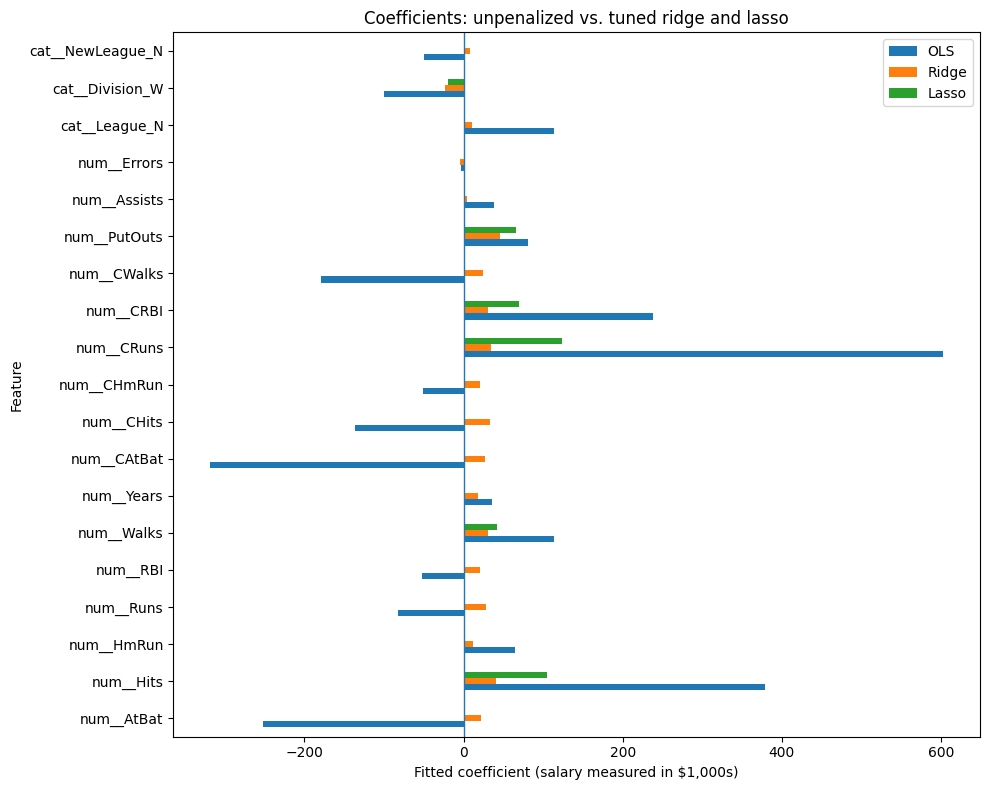

In [ ]:
plot_df = coef_table.set_index('Feature')[['OLS', 'Ridge', 'Lasso']]
plot_df.plot(kind='barh', figsize=(10, 8))
plt.axvline(0, linewidth=1)
plt.xlabel('Fitted coefficient (salary measured in $1,000s)')
plt.title('Coefficients: unpenalized vs. tuned ridge and lasso')
plt.tight_layout()
plt.show()

**Question 5:** Name two variables retained by lasso and two dropped (if available). Does a zero coefficient prove a variable has no relationship with salary? Explain why **correlated predictors** make that interpretation especially risky.

**Interpretability vs. flexibility:** Lasso may provide a shorter description of salary by using fewer features. Ridge typically keeps more predictors and may distribute weight among correlated statistics. Neither method changes a linear regression into a nonlinear one by itself; regularization constrains coefficients and therefore affects **effective complexity**.

**Bias–variance connection:** Weak regularization allows coefficients to respond strongly to a particular sample (potentially high variance). Very strong regularization suppresses important relationships (higher bias). CV tries to choose a reasonable balance.

In here: Career Runs, Career Hits, and Career At Bats are likely correlated because players who have more opportunities to bat often accumulate more hits and runs. This overlap can make OLS coefficients unstable. Ridge controls their size, while Lasso can remove redundant predictors.

### Exit ticket: answer in 3–5 sentences
A student says: *“Lasso removed five predictors from model, so those predictors do not affect salary. Also, ridge has a higher training error than linear regression, so ridge is clearly worse.”*

What is wrong with both claims? Use **training vs. test performance**, **bias–variance**, and **interpretability** in your explanation.



The linear model is unstable, and the real values that make the salary go up is going down in this value.

The Rigde is more stable than the linear model, the coef are in the right direction and values are scaled.

The lasso model removed some coef, only the correlated ones (hits, runs).

The higher the alpha, the strict the model